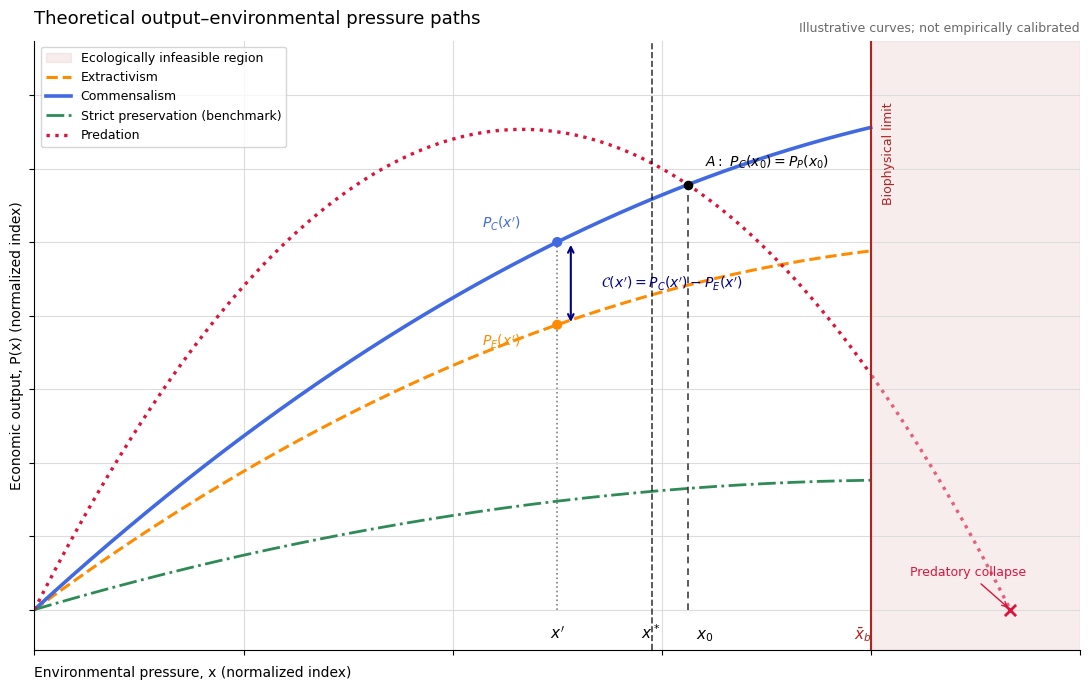

: 

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


# -----------------------------------------------------------------------------
# 1. Domínio: pressão ambiental em escala normalizada
# -----------------------------------------------------------------------------

x = np.linspace(0, 10, 1000)


# -----------------------------------------------------------------------------
# 2. Trajetórias teóricas de produção
#
# As funções são ilustrativas, não estimadas. As trajetórias comensal e
# extrativista são crescentes e côncavas no domínio ecologicamente admissível:
# P'(x) > 0 e P''(x) < 0. A trajetória predatória cresce no curto prazo, mas
# colapsa quando a degradação destrói a base produtiva.
# -----------------------------------------------------------------------------

def p_predation(z):
    return 2.80 * z - 0.30 * z**2


def p_commensalism(z):
    return 1.30 * z - 0.06 * z**2


def p_extrativism(z):
    return 1.05 * z - 0.055 * z**2


def p_strict_preservation(z):
    """Benchmark de uso econômico mínimo e baixa pressão ambiental."""
    return 0.42 * z - 0.025 * z**2


y_predation = p_predation(x)
y_commensalism = p_commensalism(x)
y_extrativism = p_extrativism(x)
y_preservation = p_strict_preservation(x)


# -----------------------------------------------------------------------------
# 3. Pontos conceituais
# -----------------------------------------------------------------------------

# Limite regenerativo/funcional do bioma. É uma restrição ecológica, não a
# igualdade entre grandezas dimensionalmente diferentes.
x_bar_b = 8.0

# Colapso da trajetória predatória: P_P(x_c) = 0, desconsiderando a raiz x = 0.
x_collapse = 2.80 / 0.30

# Ponto A: na parte positiva do domínio, o comensalismo passa a produzir mais
# que a predação. A outra interseção é a origem.
x_0 = (2.80 - 1.30) / (0.30 - 0.06)
y_A = p_commensalism(x_0)

# x* maximiza o benefício social líquido ilustrativo do regime comensal:
# W_C(x) = P_C(x) - omega*x², sujeito a x <= x_bar_b.
# O valor de omega é apenas uma calibração gráfica e deve ser substituído por
# fundamento teórico ou estimação no modelo formal.
omega = 0.05
feasible = x <= x_bar_b
w_commensal = p_commensalism(x) - omega * x**2
x_star = x[feasible][np.argmax(w_commensal[feasible])]

# Ponto usado para mostrar a vantagem comensal para uma mesma pressão x'.
x_sample = 5.0
Pc_sample = p_commensalism(x_sample)
Pe_sample = p_extrativism(x_sample)


# -----------------------------------------------------------------------------
# 4. Gráfico
# -----------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

# Região que viola a restrição ecológica do bioma.
ax.axvspan(
    x_bar_b,
    x.max(),
    color="firebrick",
    alpha=0.08,
    label="Ecologically infeasible region",
)

# As estratégias de referência são mostradas apenas no domínio admissível.
ax.plot(
    x[feasible],
    y_extrativism[feasible],
    label="Extractivism",
    linestyle="--",
    linewidth=2.2,
    color="darkorange",
)
ax.plot(
    x[feasible],
    y_commensalism[feasible],
    label="Commensalism",
    linestyle="-",
    linewidth=2.6,
    color="royalblue",
)
ax.plot(
    x[feasible],
    y_preservation[feasible],
    label="Strict preservation (benchmark)",
    linestyle="-.",
    linewidth=2.0,
    color="seagreen",
)

# A predação pode ultrapassar o limite temporariamente, até o colapso.
predation_pre_limit = x <= x_bar_b
predation_post_limit = (x >= x_bar_b) & (x <= x_collapse)
ax.plot(
    x[predation_pre_limit],
    y_predation[predation_pre_limit],
    label="Predation",
    linestyle=":",
    linewidth=2.4,
    color="crimson",
)
ax.plot(
    x[predation_post_limit],
    y_predation[predation_post_limit],
    linestyle=":",
    linewidth=2.4,
    color="crimson",
    alpha=0.65,
)


# -----------------------------------------------------------------------------
# 5. Vantagem comensal C(x') = P_C(x') - P_E(x')
# -----------------------------------------------------------------------------

ax.vlines(
    x_sample,
    0,
    Pc_sample,
    color="gray",
    linestyle=":",
    linewidth=1.2,
    zorder=1,
)
ax.scatter(
    [x_sample, x_sample],
    [Pe_sample, Pc_sample],
    color=["darkorange", "royalblue"],
    s=40,
    zorder=5,
)
ax.annotate(
    "",
    xy=(x_sample + 0.13, Pc_sample),
    xytext=(x_sample + 0.13, Pe_sample),
    arrowprops={"arrowstyle": "<->", "color": "navy", "linewidth": 1.5},
)
ax.annotate(
    r"$\mathcal{C}(x')=P_C(x')-P_E(x')$",
    xy=(x_sample + 0.13, (Pc_sample + Pe_sample) / 2),
    xytext=(x_sample + 0.42, (Pc_sample + Pe_sample) / 2),
    va="center",
    color="navy",
    fontsize=10,
)
ax.annotate(
    r"$P_C(x')$",
    xy=(x_sample, Pc_sample),
    xytext=(-54, 10),
    textcoords="offset points",
    color="royalblue",
    fontsize=10,
)
ax.annotate(
    r"$P_E(x')$",
    xy=(x_sample, Pe_sample),
    xytext=(-54, -16),
    textcoords="offset points",
    color="darkorange",
    fontsize=10,
)


# -----------------------------------------------------------------------------
# 6. Ótimo, interseção e limite ecológico
# -----------------------------------------------------------------------------

ax.axvline(x_star, color="black", linestyle="--", linewidth=1.2, alpha=0.75)
ax.annotate(
    r"$x^*$",
    xy=(x_star, 0),
    xytext=(x_star - 0.10, -0.40),
    fontsize=11,
)

ax.vlines(
    x_0,
    0,
    y_A,
    color="black",
    linestyle=(0, (4, 3)),
    linewidth=1.2,
    alpha=0.75,
)
ax.scatter(x_0, y_A, color="black", s=35, zorder=6)
ax.annotate(
    r"$A:\ P_C(x_0)=P_P(x_0)$",
    xy=(x_0, y_A),
    xytext=(12, 13),
    textcoords="offset points",
    fontsize=10,
)
ax.annotate(
    r"$x_0$",
    xy=(x_0, 0),
    xytext=(x_0 + 0.08, -0.40),
    fontsize=11,
)

ax.axvline(x_bar_b, color="firebrick", linestyle="-", linewidth=1.5)
ax.annotate(
    r"$\bar{x}_b$",
    xy=(x_bar_b, 0),
    xytext=(x_bar_b - 0.16, -0.40),
    color="firebrick",
    fontsize=11,
)
ax.annotate(
    "Biophysical limit",
    xy=(x_bar_b, 6.2),
    xytext=(8, 0),
    textcoords="offset points",
    rotation=90,
    va="center",
    color="firebrick",
    fontsize=9,
)

ax.scatter(x_collapse, 0, marker="x", color="crimson", s=65, linewidths=2, zorder=6)
ax.annotate(
    "Predatory collapse",
    xy=(x_collapse, 0),
    xytext=(-72, 24),
    textcoords="offset points",
    color="crimson",
    fontsize=9,
    arrowprops={"arrowstyle": "->", "color": "crimson", "linewidth": 1.0},
)

ax.annotate(
    r"$x'$",
    xy=(x_sample, 0),
    xytext=(x_sample - 0.07, -0.40),
    fontsize=11,
)


# -----------------------------------------------------------------------------
# 7. Estética e exportação
# -----------------------------------------------------------------------------

y_max = max(
    y_predation[predation_pre_limit].max(),
    y_commensalism[feasible].max(),
    y_extrativism[feasible].max(),
)

ax.set_title(
    "Theoretical output–environmental pressure paths",
    loc="left",
    fontsize=13,
    pad=12,
)
ax.text(
    1.0,
    1.01,
    "Illustrative curves; not empirically calibrated",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
    color="dimgray",
)
ax.set_xlabel("Environmental pressure, x (normalized index)", loc="left", labelpad=8)
ax.set_ylabel("Economic output, P(x) (normalized index)")
ax.set_xlim(0, x.max())
ax.set_ylim(-0.55, y_max * 1.18)

ax.tick_params(axis="both", which="both", labelbottom=False, labelleft=False)
ax.grid(True, color="gainsboro", linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(loc="upper left", frameon=True, fontsize=9)

fig.tight_layout()

output_file = Path("grafico_comensalismo_adaptado.png")
fig.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()